# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі запускаємо локально через [Ollama](https://ollama.com) і звертаємося до нього звичайними HTTP-запитами.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [1]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [3]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.11


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [4]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [5]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [6]:
QUESTION = "Яка столиця Франції?"

In [7]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Північній Америці, яка розташована в


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [8]:
from IPython.display import Markdown, display

display(Markdown(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"]))

Столиця Франції — це **Париж**.

### 1.4. Instruct проти Thinking: багатокрокова задача

In [9]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 251 | генерація: 0.9 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:** У кошику **9 яблук**.

=== think=True | токенів: 515 | генерація: 1.8 с
--- міркування (1223 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package is 4 apples, and there are 2 packages. So that's 4 times 2, which i

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [10]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 203 | генерація: 0.7 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** літеру «р»

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1**

=== think=True | токенів: 651 | генерація: 2.3 с
--- міркування (1541 символів), початок:
Okay, let's see. The user is asking how many times the letter "r" appears in the word "трансформер". First, I need to make sure I understand the question correctly. They want to know the count of the letter "r" in this Russian word.

Alright, so the word is "трансформер". Let me write it out: трансформер. Now, I need to check each letter one by one. Let's break it down:

1. First letter: "т" – that's a "t" in Cyrillic, right? So not an 

In [11]:
compare_thinking("З міста А в місто Б, відстань між якими 100 км, одночасно виїхали дві машини. Швидкість першої 50 км/год, другої 70 км/год. Яка відстань буде між ними в той момент, коли друга машина прибуде в місто Б?")
print("\n\n\n")
compare_thinking("Яка точна довжина екватора Землі в кілометрах?")

=== think=False | токенів: 835 | генерація: 3.0 с
--- відповідь:
Давайте розглянемо задачу:

- Відстань між містами А і Б: **100 км**
- Швидкість першої машини: **50 км/год**
- Швидкість другої машини: **70 км/год**
- Відомо, що **одночасно** виїхали дві машини.

---

### 1. Визначимо, яким буде час, коли друга машина прибуде в місто Б.

Друга машина є **швидшою**, тому вона прибуде **відразу після виїзду** з міста А.

Відстань до міста Б: **100 км**

Швидкість другої машини: **70 км/год**

Відповідно:

$$
\text{Час} = \frac{\text{Відстань}}{\text{Швидкість}} = \frac{100}{70} = \frac{10}{7} \text{ години} \approx 1.4286 \text{ години}
$$

---

### 2. Визначимо, яким буде відстань між машинами, коли друга машина прибуде в місто Б.

Після виїзду з міста А:

- Перша машина їде зі швидкістю **50 км/год**
- Друга машина їде зі швидкістю **70 км/год**
- Відстань між ними після часу $ t $:  
  $$
  \text{Відстань} = 100 - (50t + 70t) = 100 - 120t
  $$

Після часу $ \frac{10}{7} $ години:

$$


Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

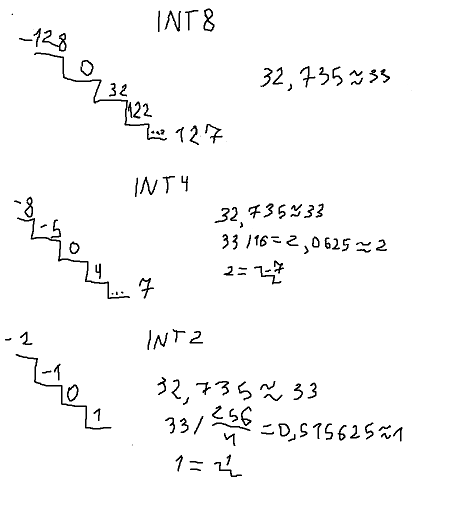

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [12]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [13]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: NVIDIA A100-SXM4-80GB


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [14]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
# MODEL_ID = "Qwen/Qwen3-1.7B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [15]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [16]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

...

int8: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [17]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)

summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.04,8.64,17.86,2.67,2.40,56.57,23.98
int8,4.42,5.01,11.08,2.67,2.40,58.25,26.17
int4,2.73,3.31,12.80,2.81,2.77,55.90,29.79
int2,1.81,2.39,7.34,57886.75,34008696.00,0.18,0.11


In [30]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=summary)

https://docs.google.com/spreadsheets/d/1tCMAt9OeuYr3nBiG2jD2raPE8_KPOLgD_Nuawocd6ns/edit#gid=0


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

In [ ]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [ ]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [ ]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [ ]:
VOTES = {1: "B", 2: "=", 3: "=", 4: "=", 5: "="}

In [23]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,int4
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,однаково
2,Explain in three sentences why the sky is blue.,fp16,int4,однаково
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,однаково
4,Write a Python function that checks whether a ...,int4,fp16,однаково


fp16 краща: 0, int4 краща: 1, однаково: 4


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [24]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter° infinitely h°°° LeonenniehsSP histricthshshshsinwehouseweg boundaries:
:
hshs:
hshs:
hs:
:
sd:
:
���housesdsdsd had rest rest rest:househouse::hs rest house  restwnhs: hood rest, so again pearl, b and either either between and sh nuts house -sd sd:sdss:: “sd\ rest:
 rest in: again rest, : [...] ... : ( : again pearl rest house,\' ...  pearl a house rest, a: rest, rest, rest ... A studhousehousehousehouse ,, which whichtin,, of thehouse,house,housesshousehouse which which ... againsd ...househousehousehousehousehousehousehousehousehouse usedue < house house again ... house,uchhouse ...house, ... huthousehousehousehousehousehousehousehousehousehousehousehousehousehousehousehousehouse

...

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ mil\'\'\' \\'\' \ - \ \ \ \ \'\'\'  \ \ \ - \8  \     \'\'\'\' \'\'\'\'\'\'\'\'\'\'\'\'\'\'\'\'\'\'\'\'\'\'\'\'\' \'\'\' \'\' 02\'\'\'\'\'\'\'\'\'\'\'\'\'\'\'\'\'\'\'\'\'  \'\'   2\'  \   \' ``   1                   part -8\'\n      s   国民  \  \' 国民\'国民\'\'\'\'\'\'\'\'\'\'\'\'\'\'\\\'S \'\'\'\'\' \' `` \'\'\'\'\'\'\'

### 3.0. Мої відповіді

1. **У розділі 1.5 демо модель помиляється, рахуючи літеру «р» у слові «трансформер», — причому і без міркувань, і з ними. Поясніть, чому. Підтвердіть пояснення кодом.**

Модель помиляється в обох режимах, бо фізично не бачить тексту по літерах, а сприймає його токенами. Для неї `трансформер` - це не 11 літер, а просто кілька числових id, тому без міркування вона вгадує результат навмання. Якщо увімкнути міркування, модель намагається розділити слово, але через свою базову сліпоту починає галюцинувати, вигадує хибне написання і сама себе плутає, тому тут Chain of Thought не рятує. Нижче в клітинці з кодом показано, як саме токенізатор розбиває це слово і як його реально бачить модель.

In [25]:
word = "трансформер"
tokens = tokenizer.tokenize(word)
token_ids = tokenizer.encode(word, add_special_tokens=False)

print(f"Слово: {word}")
print(f"Токени: {tokens}")
print(f"ID токенів: {token_ids}")

Слово: трансформер
Токени: ['ÑĤ', 'ÑĢÐ°Ð½', 'Ñģ', 'ÑĦÐ¾ÑĢÐ¼', 'ÐµÑĢ']
ID токенів: [1792, 34582, 2247, 56619, 7599]


2. **Як у розділі 2.4 демо змінюються перплексія й метрики перекладу від fp16 до int2? Між якими варіантами стрибок найбільший?**

Квантизація робить модель легшою, стискаючи та округлюючи значення ваг, що суттєво зменшує її обсяг та пікове споживання VRAM. Але через необхідність постійно розпаковувати ці стиснуті числа під час роботи, швидкість генерації tokens/s знижується. Перплексія показує рівень розгубленості моделі, BLEU оцінює точність перекладу на рівні цілих слів, а chrF на рівні окремих символів. Як видно з таблиці, INT8 та INT4 чудово зберігають якість генерації та перекладу, але екстремальне стиснення до INT2 повністю ламає нейромережу, змушуючи перплексію злітати в космос, а метрики BLEU та chrF падають майже до нуля.

3. **Чи однаково зростає перплексія для англійської й української? Порівняйте з висновком зі слайду «Де просідає якість».**

У форматах INT8, INT4 показники для обох мов тримаються стабільно, але при стисненні до INT2 перплексія англійської стрибає майже до 60 тисяч, а української майже до 35 мільйонів. Це підтверджує правило оптимізації, що при сильному стисненні якість найсильніше просідає на неанглійських мовах. Англійська є базовою для тренувальних даних, тому якісь примітивні зв'язки для неї зберігаються довше. Українська мова представлена в моделі менше, а її кириличні слова розбиваються на більшу кількість дрібних токенів. Тому при квантизації до 2 біт слабші нейронні зв'язки, які відповідали за українську логіку, просто стираються. Це повністю збігається з висновком зі слайду лекції, при квантизації першими ламаються мови з нелатинською абеткою, зокрема й українська.


4. **Чи збігається ваш вибір у сліпому порівнянні (розділ 2.5 демо) з тим, що показали автоматичні метрики? Чи помітили ви різницю там, де метрики майже не змінилися, — або навпаки?**

Мій вибір у сліпому порівнянні підтверджує результати автоматичних метрик. Різниця між оригінальною моделлю fp16 та квантованою int4 візуально майже непомітна. Як і показали метрики, обидві моделі генерують практично ідентичний і робочий код та однаково добре формулюють думки англійською. Моделі однаково туплять на складніших україномовних завданнях, у 4-му запиті обидва варіанти припускаються помилок дублюють слова та погано відмінюють. Загалом деградації логіки при стисненні до 4 біт людським оком не видно.

5. **Знайдіть у таблиці перекладів (розділ 2.4 демо) правильний переклад, який відрізняється від еталона словами. Як на нього реагують BLEU і chrF?**

Усі робочі формати fp16, int8, int4 видали змістовно правильний переклад, тоді як в int2 утворився нечитабельний набір символів. Метрика BLEU виявилася дуже суворою, її максимум становить лише 29.79 в int4, оскільки вона жорстко штрафує за відсутність точного збігу цілих слів. Метрика chrF працює м'якше і показує результат 55–58 балів. Вона оцінює збіги на рівні частин слів та символів. Якщо модель генерує `читади` замість `читати`, chrF зараховує спільний корінь, що робить цю метрику об'єктивнішою для української мови.

6. **У скільки разів зменшилася памʼять у таблиці розділу 2.4 демо і чому не рівно вдвічі, вчетверо й увосьмеро? Чи стала генерація швидшою?**

Від fp16 пам'ять моделі зменшилася до 4.42 ГБ в int8, до 2.73 ГБ в int4 та до 1.81 ГБ в int2. Розмір падає не рівно кратно бітам, оскільки квантизуються ваги лінійних шарів, тоді як інші компоненти (ембединги, нормалізації та вихідний шар) залишаються у форматі 16 біт. Генерація стала повільнішою, оскільки архітектура відеокарти не підтримує прямих обчислень зі стиснутими форматами, через що модель змушена постійно витрачати ресурси на розпакування ваг назад у 16-бітний вигляд перед кожним множенням.

7. **Чому Base-модель у розділі 1.2 відповідає на питання новими питаннями? Сформулюйте промпт так, щоб Base-модель усе ж дала відповідь. Наведіть код і результат.**

Base-модель відповідає на питання новими питаннями, оскільки вона не проходила спеціального навчання для ведення діалогу чи відповідей на запити користувача. Її базова функція полягає у продовжені тексту. Коли вона бачить питання, то сприймає його як початок тесту або анкети і просто генерує наступні схожі запитання. Щоб змусити її дати відповідь, потрібно сформулювати запит у вигляді незавершеного стверджувального факту, давши моделі змогу дописати потрібне слово.

In [26]:
QUESTION = "Столиця Італії — Рим.\nСтолиця Німеччини — Берлін.\nСтолиця Франції — "
print(generate_raw(BASE_MODEL, QUESTION, max_tokens=3))

 Париж


8. **Скільки токенів і часу забрали міркування в розділі 1.4 порівняно з відповіддю без міркувань? Чому модель міркує англійською, хоча питання українською?**

У режимі без міркувань генерація зайняла 1.5 секунди і 235 токенів, тоді як із міркуваннями витрати ресурсів зросли більш ніж удвічі до 3.2 секунди та 503 токенів. Модель формує внутрішній логічний ланцюжок англійською мовою через специфіку навчальних даних, більшість датасетів для розвитку математичної логіки є англомовними, та заради суттєвої економії, латиниця токенізується набагато ефективніше за українську кирилицю, що дозволяє моделі витрачати менше токенів на власні роздуми та швидше переходити до генерації фінальної відповіді.

9. **Знайдіть задачу, на якій режим міркування дає правильну відповідь, а без нього модель помиляється. Наведіть промпт і обидві відповіді.**

Для прикладу ми використали задачу на знаходження середньої швидкості автомобілю. Без міркувань модель намагається вгадати формулу, робить логічну помилку у відстані та видає хибні 24 км/год. З увімкненим міркуванням модель створює послідовний ланцюг думок і покроково розписує задачу, завдяки чому сама наводить себе на правильну відповідь 48 км/год.

In [27]:
PROMPT = "Автомобіль проїхав шлях з міста А в місто Б зі швидкістю 60 км/год, а повернувся назад зі швидкістю 40 км/год. Яка його середня швидкість за всю поїздку?"

compare_thinking(PROMPT)

=== think=False | токенів: 495 | генерація: 1.8 с
--- відповідь:
Щоб знайти середню швидкість автомобіля за всю поїздку, необхідно використати формулу середньої швидкості:

$$
\text{Середня швидкість} = \frac{\text{Відстань}}{\text{Час}}
$$

При цьому:

- Відстань між містами А і Б: $ S = v_1 \cdot t_1 + v_2 \cdot t_2 $
- Час поїздки: $ t = \frac{S}{v_1} + \frac{S}{v_2} $

Однак, якщо відстань між містами А і Б дорівнює $ S $, то:

- Час на зворотному шляху: $ t_2 = \frac{S}{v_2} $
- Час на зворотному шляху: $ t_1 = \frac{S}{v_1} $

Таким чином, середня швидкість:

$$
\text{Середня швидкість} = \frac{S}{\frac{S}{v_1} + \frac{S}{v_2}} = \frac{1}{\frac{1}{v_1} + \frac{1}{v_2}}
$$

Підставляємо значення:

- $ v_1 = 60 \, \text{км/год} $
- $ v_2 = 40 \, \text{км/год} $

$$
\text{Середня швидкість} = \frac{1}{\frac{1}{60} + \frac{1}{40}} = \frac{1}{\frac{2 + 3}{120}} = \frac{1}{\frac{5}{120}} = \frac{120}{5} = 24 \, \text{км/год}
$$

**Відповідь: 24 км/год**

=== think=True | токенів: 1559 

10. **У функціях generate_raw і chat (розділ 1.1) стоять temperature: 0 і seed: 1. Навіщо?**

Ці параметри потрібні для абсолютної детермінованості та відтворюваності результатів роботи. Значення `temperature: 0` вимикає випадковість і забарвленість моделі, а `seed: 1` фіксує початковий стан генерації, завдяки чому при кожному запуску коду буде отримано ідентичні відповіді.

11. **Чому в секції 2 використовуємо fp16, а не bf16? Що показує torch.cuda.get_device_capability() на T4 і як це з цим повʼязано?**

Ми використовуємо fp16, а не bf16, тому що відеокарта Tesla T4 апаратно не підтримує bf16, тому fp16 залишається єдиним базовим варіантом із рідним прискоренням. Функція torch.cuda.get_device_capability() повертає версію архітектури відеокарти. Це пов'язано з роботою коду, оскільки оптимізовані CUDA-ядра бібліотеки квантизації вимагають архітектуру покоління 8 і вище, скрипт відловлює застарілу версію T4 (< 8) і примусово підміняє несумісний апаратний розпакувальник ваг на програмну PyTorch-функцію unpack_weights, дозволяючи успішно запускати стиснуті моделі без помилок компіляції.


12. **Скільки параметрів у моделі з розділу 2.1 і скільки памʼяті має займати її fp16-версія за формулою з лекції? Порівняйте з «памʼяттю моделі» в таблиці розділу 2.4.**

У моделі `Qwen3-4B-Instruct-2507` 4 мільярди параметрів, і оскільки версія fp16 використовує 2 байти на кожну вагу, за базовою формулою вона мала б займати 8 мільярдів байтів. Якщо перевести це у гігабайти поділивши на $1024^3$, виходить близько 7.45 ГБ. Проте в таблиці розділу 2.4 вказано фактичний розмір 8.04 ГБ. Ця відчутна різниця виникає переважно через те, що маркування 4B є округленим значенням, тоді як реальна кількість параметрів є більшою завдяки гігантським матрицям ембедингів для словника токенів. Крім того, під час завантаження моделі на відеокарту фреймворк PyTorch додатково резервує частину пам'яті під службові метадані та вирівнювання тензорів.


13. Що таке перплексія (розділ 2.2) і чому її не можна порівнювати між англійською й українською? Порахуйте перплексію fp16-моделі на випадковому наборі слів замість осмисленого тексту й поясніть результат.

Перплексія - це метрика, яка відображає ступінь невпевненості моделі під час передбачення наступного токена у послідовності. Чим нижче значення, тим краще модель моделює мову. Порівнювати перплексію між англійською та українською мовами некоректно через принципову різницю в токенізації. Словники LLM зазвичай оптимізовані під англійську, де одне слово часто відповідає одному токену. А українські слова розбиваються на кілька дрібних токенів. Оскільки перплексія усереднюється на кожен згенерований токен, різна щільність токенізації робить пряме математичне порівняння цих показників безглуздим.

In [28]:
random_text = "Темно світло йти карусель жовтень лавка"

inputs = tokenizer(random_text, return_tensors="pt").to("cuda")

model = AutoModelForCausalLM.from_pretrained(
    "Qwen/Qwen3-4B-Instruct-2507",
    torch_dtype=torch.float16,
    device_map="cuda"
)

with torch.no_grad():
    outputs = model(**inputs, labels=inputs["input_ids"])
    loss = outputs.loss
    perplexity = torch.exp(loss)

print(f"Перплексія на випадковому тексті: {perplexity.item():.2f}")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Перплексія на випадковому тексті: 142.44


Ми отримали дуже високий показник перплексії. Це відбувається тому, що ці слова жодним чином не пов'язані між собою семантично, тоді як мовна модель навчалася передбачати логічні та граматично узгоджені послідовності токенів.

14. Чому «пік VRAM» у таблиці розділу 2.4 більший за «памʼять моделі»? Що ще, крім ваг, займає памʼять під час генерації?

Пік VRAM більший за базову пам'ять моделі, оскільки під час генерації тексту додаткове місце динамічно виділяється під KV-кеш та проміжні обчислення. KV-кеш зберігає вже розраховані стани для попередніх токенів, щоб не перераховувати їх заново і пришвидшити процес, а проміжні активації - це тимчасові дані та тензори, що виникають під час проходження інформації між шарами нейромережі.

15. Скільки разів у сліпому порівнянні (розділ 2.5) ви обрали fp16, int4 чи «однаково»? Наскільки впевнено можна робити висновки з 5 порівнянь і скільки їх знадобилося б для надійного висновку?

У сліпому порівнянні варіант однаково було обрано 4 рази, варіант int4 1 раз, а fp16 взагалі не було обрано. Робити висновки на основі 5 порівнянь неможливо, така вибірка є занадто малою та статистично незначущою. Для надійного та об'єктивного висновку щодо впливу квантизації на якість генерації необхідно провести значно більшу кількість тестувань на різнопланових завданнях, бажано із залученням кількох незалежних оцінювачів.

16. Як саме «ламається» модель у int2 (розділ 2.6)? Опишіть типові помилки у відповідях. Чи помітні їхні ознаки вже в int4?

Модель в int2 зазнає сильної деградації. Замість осмисленого українського перекладу вона генерує хаотичний набір англійських літер, зациклені токени та зламану пунктуацію. Текст стає абсолютно нечитабельним і повністю втрачає сенс. У моделі int4 цих ознак колапсу ще зовсім не помітно, вона зберігає структуру мови та успішно виконує завдання.

17. Повторіть секцію 2 з меншою моделлю (наприклад, Qwen/Qwen3-1.7B). Чи сильніше квантизація бʼє по меншій моделі? Порівняйте перплексію й chrF з результатами для 4B.

Так, квантизація набагато сильніше б'є по меншій моделі, оскільки в ній менше параметрів для компенсації втраченої точності ваг. Якщо у моделі 4B при стисненні до int4 перплексія зросла зовсім незначно, то у версії 1.7B вона підскочила майже вдвічі. Щодо якості перекладу за метрикою chrF, то менша нейромережа взагалі не впоралася із завданням навіть у найкращому форматі fp16, показавши дуже низькі бали, тоді як велика модель стабільно зберігала високу якість тексту аж до повного зламу у форматі int2.

* B4 модель

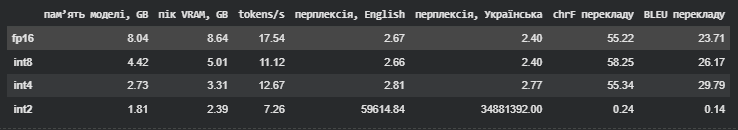
* B1.7B модель

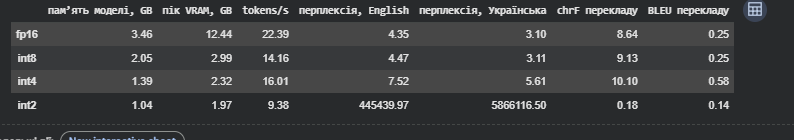

18. Поясніть принцип параметру OLLAMA_NUM_PARALLEL в ollama з демо?

Параметр OLLAMA_NUM_PARALLEL визначає кількість запитів, які Ollama може обробляти одночасно. За замовчуванням запити зазвичай виконуються по черзі. Якщо збільшити це значення, модель зможе паралельно генерувати відповіді для кількох користувачів одночасно, але це вимагатиме додаткової відеопам'яті, оскільки для кожного паралельного потоку створюється окреме контекстне вікно.

19. Чому майже всі сучасні моделі зберігаються в bf16?

Формат bf16 створений спеціально для нейромереж, щоб зменшити вагу моделі без ризику помилок переповнення. Це досягається шляхом збереження такого ж великого діапазону чисел, як у fp32, за рахунок зменшення мантиси. Хоча точність дробової частини при цьому дещо знижується, це практично не впливає на кінцеву якість генерації, натомість суттєво економить відеопам'ять та прискорює обчислення.

20. Для чого всі рантайми моделей слідують протоколу OpenAI? Як це повʼязано з ChatGPT?

Рантайми використовують протокол OpenAI, оскільки завдяки популярності ChatGPT він став фактичним стандартом в індустрії. Це дозволяє миттєво підключати будь-які локальні моделі до існуючих програм та інтерфейсів, створених для ChatGPT, без необхідності переписувати код.

### 4.0. Локальна модель і власний застосунок

#### 4.1. Залізо

In [29]:
import pandas as pd
from IPython.display import display

hardware_data = {
    "Компонент": [
        "Процесор (CPU)",
        "Обсяг RAM",
        "Відеокарта (GPU)",
        "Обсяг VRAM",
        "Пропускна здатність (VRAM)"
    ],
    "Значення": [
        "Intel Core i5-4590",
        "8 ГБ",
        "NVIDIA GeForce GTX 1060",
        "3 ГБ",
        "192 ГБ/с"
    ],
    "Джерело": [
        "AIDA64",
        "AIDA64",
        "AIDA64",
        "AIDA64",
        "Характеристики відеокарти (Rozetka)"
    ]
}

df = pd.DataFrame(hardware_data)
display(df)

,Компонент,Значення,Джерело
0,Процесор (CPU),Intel Core i5-4590,AIDA64
1,Обсяг RAM,8 ГБ,AIDA64
2,Відеокарта (GPU),NVIDIA GeForce GTX 1060,AIDA64
3,Обсяг VRAM,3 ГБ,AIDA64
4,Пропускна здатність (VRAM),192 ГБ/с,Характеристики відеокарти (Rozetka)


#### 4.2. Розрахунок

Моя відеокарта GTX 1060 має 3 ГБ пам'яті. Оскільки ОС та фонові процеси завжди забирають частину пам'яті на відмальовку інтерфейсу, безпечно виділити під модель близько 2 ГБ вільної VRAM.

Спочатку вирахуємо, якого максимального розміру модель поміститься в цей ліміт. Використовуємо формулу з лекції: Пам'ять (GB) = P * (Q / 8) * (1 + O).
Оскільки моя відеокарта має доволі обмежений обсяг пам'яті, найбільш доцільно буде обрати квантизацію 4 біти. Для мого заліза це найкращий компроміс, такий формат економить пам'ять, але при цьому зберігає якість відповідей моделі. Також закладаю максимальний запас 30% на KV-кеш та рантайм.

Підставляємо значення:
2 ГБ = P * (4 / 8) * (1 + 0.3)
2 = P * 0.5 * 1.3
2 = P * 0.65
P = 2 / 0.65 = 3.07 мільярда параметрів.

Висновок: у мою відеокарту вмістяться моделі розміром до 3 мільярдів параметрів у квантизації int4. Більші моделі або менше стиснення призведуть до нестачі пам'яті для контексту.

Стеля швидкості генерації:
Пропускна здатність моєї пам'яті становить 192 ГБ/с. За формулою tokens/s = Пропускна здатність / байти на токен розрахуємо стелю для моделей, які підходять під моє залізо.

* Для моделі на 1.5 млрд параметрів: пропускна здатність / (P * $\frac{Q}{8}$) = 192 / (1.5 * $\frac{4}{8}$) = 192 / 0.75 = 256 токенів/с.
* Для моделі на 3 млрд параметрів: пропускна здатність / (P * $\frac{Q}{8}$) = 192 / (3 * $\frac{4}{8}$) = 192 / 1.5 = 128 токенів/с.

Оскільки реальна швидкість зазвичай становить 60-90% від теоретичної, можна очікувати генерацію на рівні 80–200 токенів на секунду залежно від кінцевого вибору моделі.

#### 4.3. Вибір моделі й рантайму

На основі розрахунків було обрано такі компоненти для створення застосунку:

* Рантайм: Ollama. Він працює як фоновий процес, споживає мінімум оперативної пам'яті та автоматично надає необхідний OpenAI-сумісний API.
* Модель та розмір: Qwen2.5-1.5B. Оскільки розрахована стеля 3 млрд параметрів, вибір 1.5-мільярдної моделі є безпечнішим. Вона займає приблизно 1 ГБ, залишаючи понад 1 ГБ вільної VRAM для KV-кешу.
* Квантизація та формат: int4 у форматі GGUF. Формат GGUF оптимізований для роботи з Ollama, а 4-бітне стиснення дозволяє вмістити модель у мою відеокарту без критичної втрати якості генерації.
* Тип моделі: Я обрав Instruct-версію, оскільки цільовий застосунок вимагає від моделі розуміння інструкцій, ведення діалогу та виконання команд, а не простого продовження тексту.
* Режим міркування: Не потрібен. Reasoning-моделі генерують довгі приховані ланцюжки думок перед відповіддю. Через мій жорсткий ліміт вільної пам'яті це дуже швидко переповнить KV-кеш і призведе до критичного падіння швидкості.

#### 4.4. Вимірювання до оптимізації

Тестування моделі `qwen2.5:1.5b-q4_0` продемонструвало стабільні показники генерації. Для одного клієнта швидкість становить 64.7 tok/s. Збільшення кількості паралельних запитів майже не впливає на індивідуальну швидкість, яка тримається в межах 64.3 – 64.8 tok/s. Загальна пропускна здатність *throughput* сервера досягає піку у 62.1 tok/s при 4 клієнтах.

Розрахована у пункті 1.2 теоретична стеля становила 256 токенів/с. Хоча фактична швидкість є в 4 рази нижчою, це тому що формула використовує ідеальні умови пропускної здатності відеокарти і ігнорує реальні обмеження. Ресурс відеокарти пасивно використовується операційною системою також, і може бути зарезервований під інші потреби.

Для перевірки якості було створено 10 промптів, які імітують роботу майбутнього застосунку, роль якого буде полягати у генерації тестів на базі наданого блоку теоретичних відомостей. Завдання вимагало від моделі аналізувати фрагмент тексту, придумати тестове запитання і варіанти відповідей і згенерувати самарі у форматі JSON.

*До критеріїв оцінки належали:*

1. Відповідність формату JSON.
2. Фактологічна правильність згенерованого JSON.
3. Наявність 4 варіантів відповідей.
4. Точність запитання відносно тексту.

Результатом є 10 із 10 успішних генерацій. Квантизація не погіршила якість моделі.

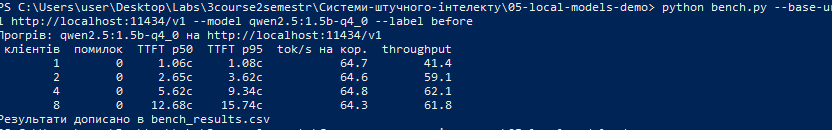

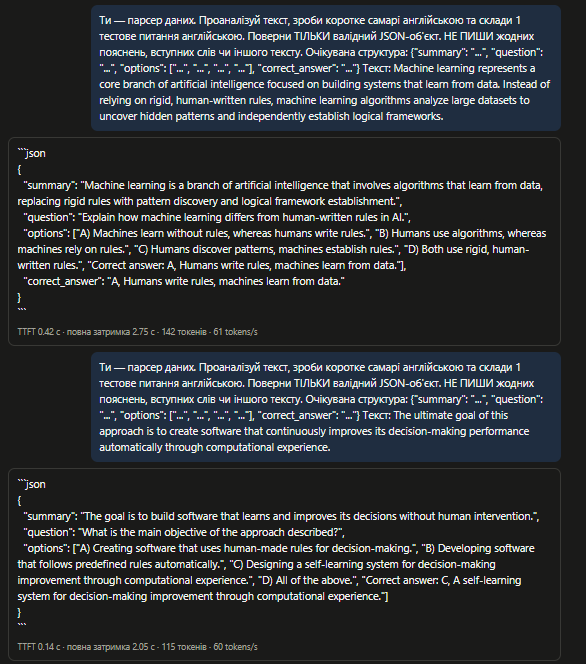

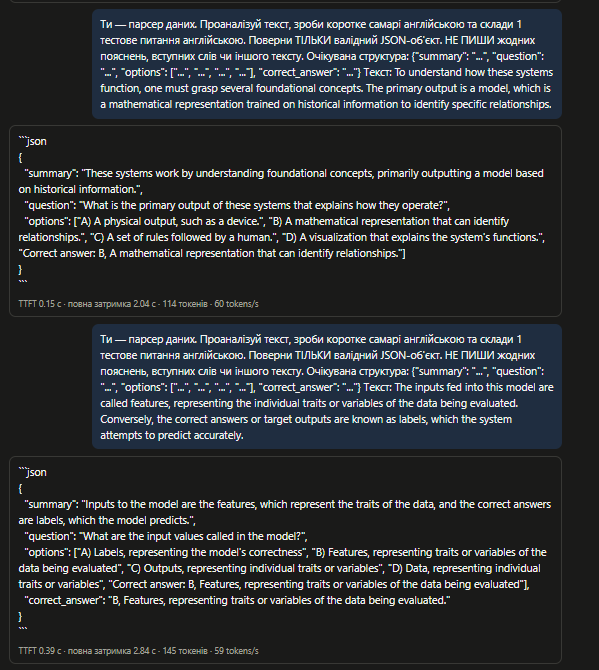

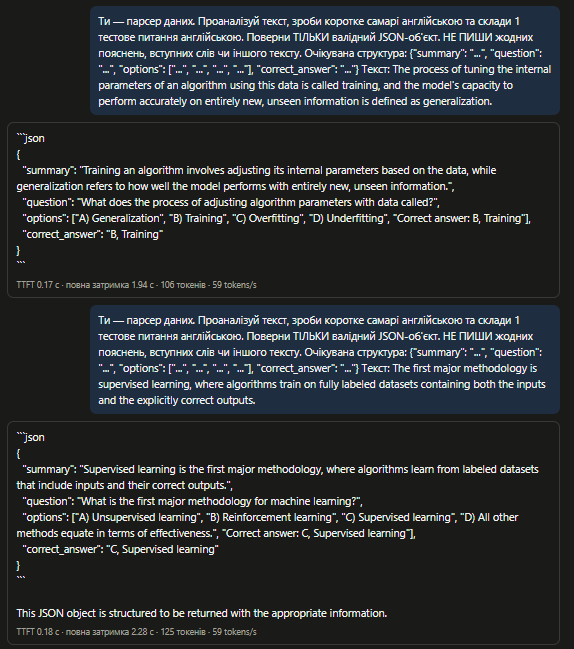

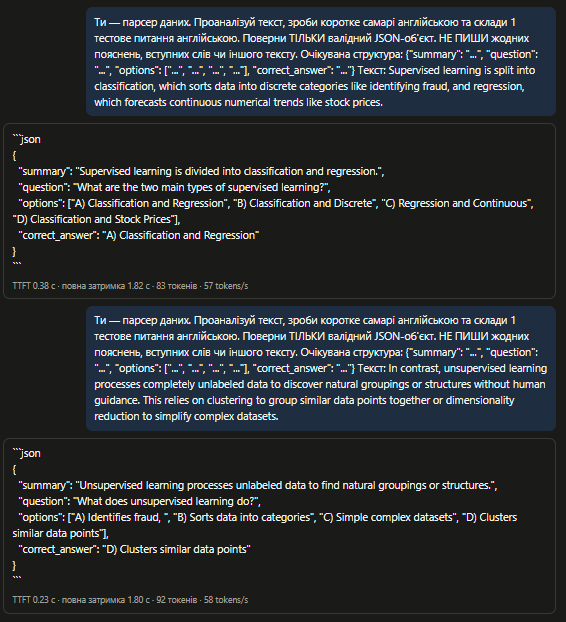

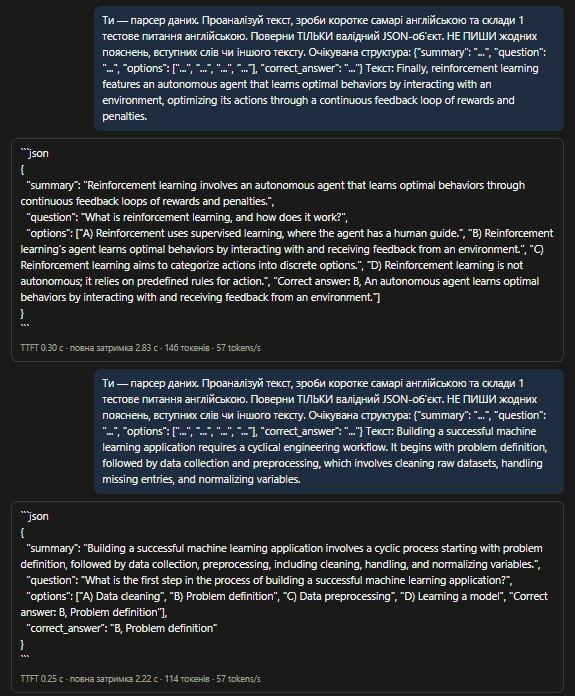

#### 4.5. Оптимізація і вимірювання після

**Аналіз шляхів оптимізації**

Оскільки базова модель qwen2.5:1.5b-q4_0 вже продемонструвала гарну точність виконання інструкцій надавши 10/10 валідних JSON-об'єктів, покращувати якість відповідей недоцільно. Головна мета оптимізації - підвищення швидкості генерації *tokens/s* та максимальне зменшення навантаження на обмежену відеопам'ять.

Для досягнення цієї мети було проаналізовано такі підходи:

*   **Зміна квантизації на int8**: Є недоцільним. Менший рівень стиснення подвоїть фізичний розмір ваг моделі в пам'яті. На відеокарті GTX 1060 із загальним обсягом 3 ГБ це залишить критично мало місця для KV-кешу та потреб операційної системи, що призведе до різкого падіння швидкості через нестачу VRAM.
*   **Використання MoE-моделі**: Є недоцільним. Специфіка архітектури MoE вимагає завантаження всіх параметрів у відеопам'ять, навіть якщо під час генерації працює лише їхня частина. Найменші ефективні MoE-моделі мають від 2.7 млрд загальних параметрів, що гарантовано викличе переповнення пам'яті.
*   **Зміна рантайму**: Відхилено. Ollama базується на рушії llama.cpp і працює з форматом GGUF, який наразі є найбільш оптимізованим стандартом для запуску на слабкому споживчому залізі. Альтернативні високопродуктивні рантайми вимагають значно більшого резерву VRAM лише для власного старту, що є неможливим у поточних апаратних умовах.
*   **Використання меншої моделі**: Є доцільним для тустування. Перехід на мікро-модель qwen2.5:0.5b дозволить вивільнити максимум VRAM і має суттєво пришвидшити генерацію. Головне завдання вимірювання полягає у перевірці, чи зберегла ця версія достатньо інтелекту для формування валідного JSON.




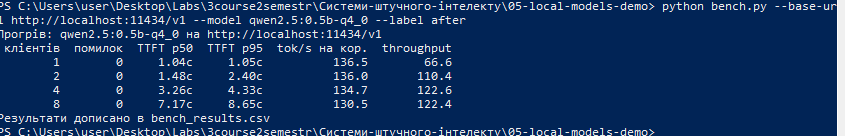

Перехід на оптимізовану модель `qwen2.5:0.5b-q4_0` забезпечив двократне зростання швидкості генерації, на 8 клієнтах індивідуальний показник досяг 130.5 tok/s, що майже вдвічі більше за попередню версію. Загальна пропускна здатність сервера також пропорційно зросла. Затримка до появи першого токена (TTFT p50) для одного клієнта складає комфортні 1.04 секунди, проте при паралельному навантаженні у 8 запитів вона очікувано збільшується до 7.17 секунди.

Хоча перехід на мікро-модель qwen2.5:0.5b-q4_0 удвічі пришвидшив генерацію, якість виконання інструкцій деградувала. Модель ігнорує вимогу повертати виключно код, постійно додаючи зайвий вступний текст перед JSON-об'єктом. Згенеровані варіанти відповідей стали надто короткими та примітивними. Головним недоліком є поява фактологічних галюцинацій: система обирає хибні правильні відповіді, що суперечать вихідному тексту, наприклад «Undirected» або вигадане «Building a final image». Через таке руйнування логіки застосунку оптимізація меншою моделлю визнана недоцільною, тому фінальним вибором залишається базова та стабільна qwen2.5:1.5b-q4_0.

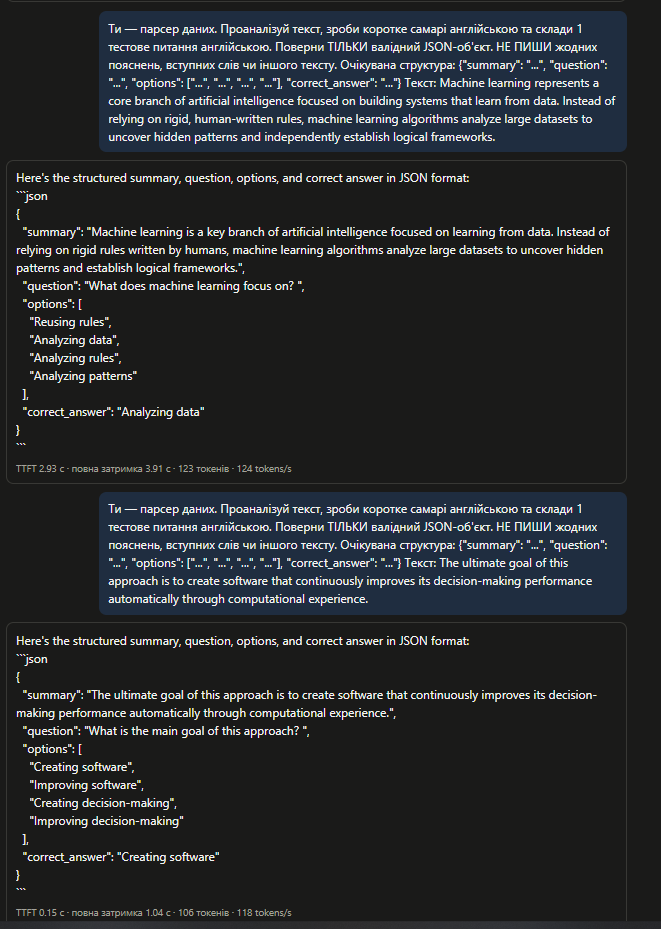


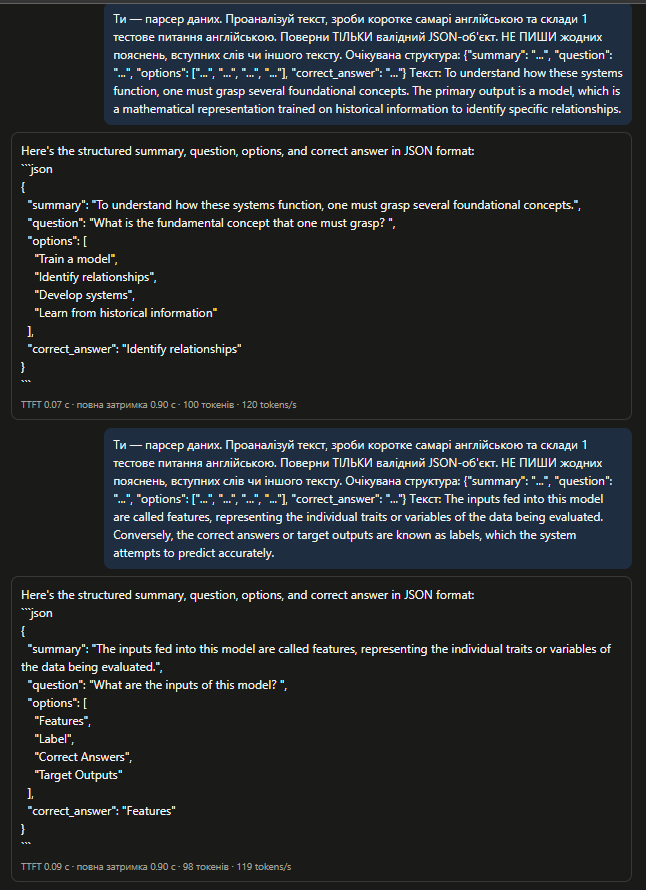

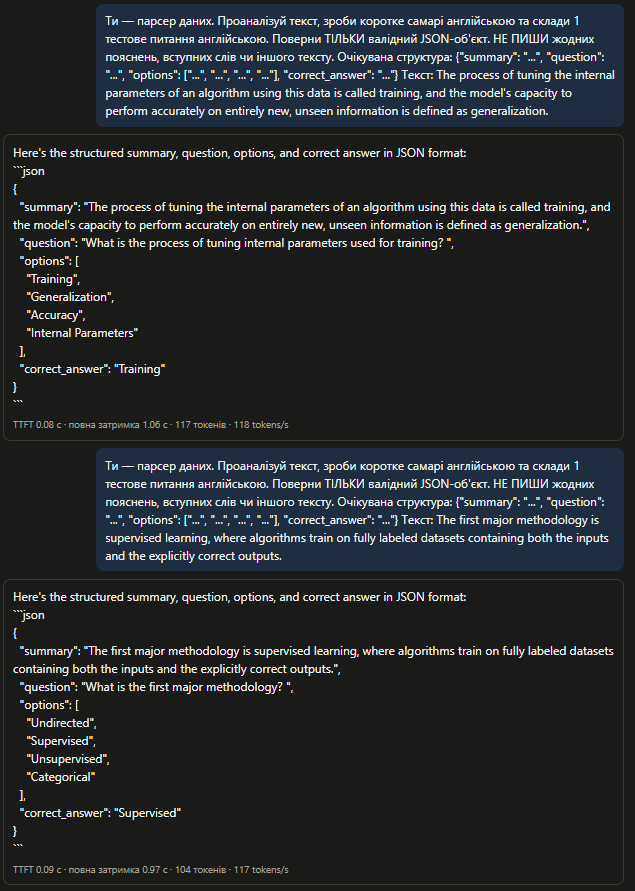

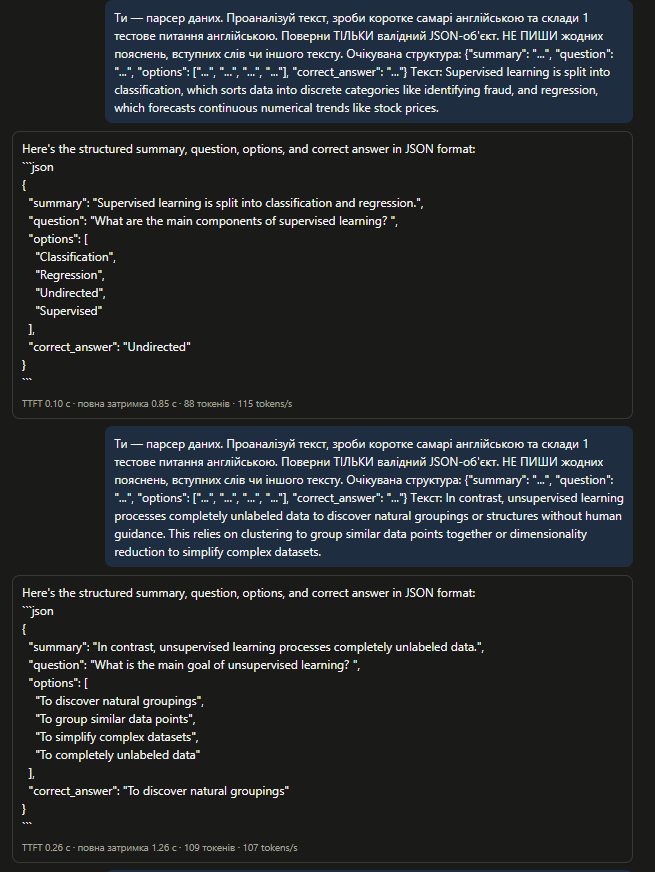

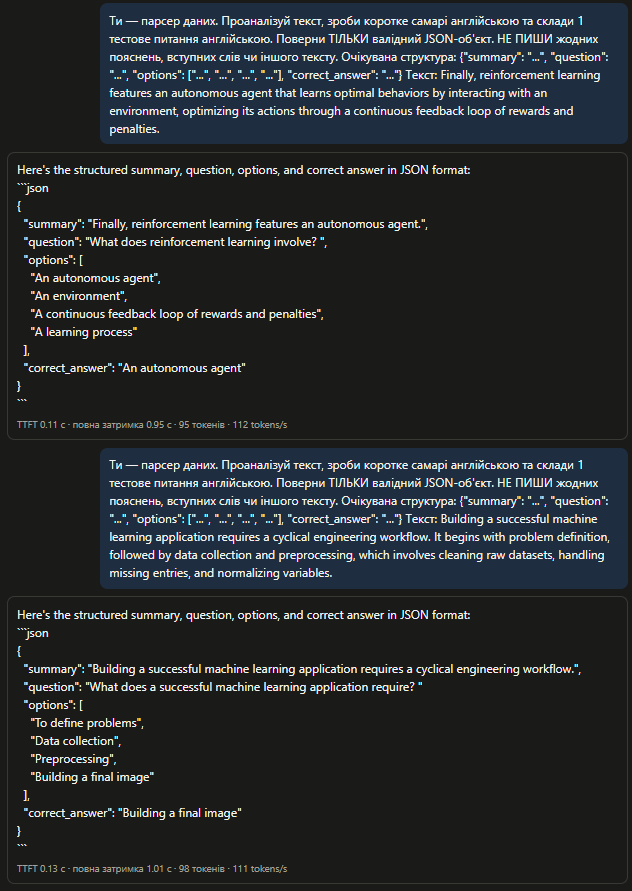

#### 4.6. Застосунок — що робить і як працює, параметри генерації:

Було розроблено вебзастосунок для генерування інтерактивних тестів на основі введеного тексту. Він працює локально через OpenAI-сумісний API з малою моделлю qwen2.5:1.5b-q4_0. Головна мета - перетворення статей, навчальних матеріалів чи документації на зручні тести для перевірки знань із суворою валідацією правильних і хибних відповідей.

**Як працює архітектура:**

* *Динамічний чанкінг:* Щоб мала модель не втрачала фокус, великий текст розбивається на логічні абзаци. Кількість частин дорівнює кількості замовлених питань, щоб кожне стосувалося нового фрагмента.
* *Механізм стійкості:* Якщо модель повертає битий JSON або плейсхолдери, наприклад, "Option 1", система робить до 5 повторних спроб. Якщо модель остаточно зациклюється, генерується питання-заглушка, щоб тест не зламався.
* *Сувора валідація:* Агресивний парсинг витягує JSON, навіть якщо модель додала зайвий текст. Варіанти відповідей перемішуються, щоб правильний завжди був на випадковій позиції.
* *Локальне збереження:* Історія згенерованих тестів автоматично записується в localStorage браузера.

**Параметри генерації та стратегія промптингу:**

* *temperature: 0.1:* Оптимальний баланс. При 0.2 і вище мала модель починає галюцинувати та вигадувати факти, а при 0.05 видає криві граматичні конструкції.
* *max_tokens: 300:* Жорсткий запобіжник від зациклення. Одне питання займає близько 120–150 токенів, тому ліміт у 300 не дає моделі безкінечно генерувати сміття.
* *Zero-shot промптинг:* Від використання few-shot відмовився, оскільки модель на 1.5B просто сліпо копіювала шаблон. Замість цього використовується пряма вказівка з чітким каркасом JSON.
* *Якір EXCLUSIVE:* У промпті прописана жорстка вимога використовувати виключно наданий текст, щоб модель не тягнула факти зі своєї бази знань.
* *Без режиму мислення:* Для такої малої моделі це надто складно, вона плутається у власних роздумах і ламає структуру JSON.
* *Мовна адаптація:* Застосунок налаштовано суто під англійську мову. Тестування показало, що українською мовою модель генерує нелогічні питання та безглузді варіанти відповідей незалежно від налаштувань.

#### 4.7. Перевірка та демонстрація

**Тестові сценарії:**

* *Вхідні дані:*

  - *Текст:* Artificial intelligence is the intelligence of machines or software, as opposed to the intelligence of human beings or animals. AI applications include advanced web search engines, recommendation systems, understanding human speech, self-driving cars, and generative tools. The concept of AI was formally founded as an academic discipline in 1956 at a workshop held at Dartmouth College. The researchers at Dartmouth, including John McCarthy and Marvin Minsky, coined the term 'artificial intelligence'. Today, AI is used in almost every industry, from healthcare, where it helps in diagnosing diseases, to finance, where algorithms detect fraudulent transactions. Machine learning, a subset of AI, involves training algorithms on large amounts of data so they can learn patterns and make predictions.
  - *Параметри:* 5 питань, medium складність.
  - *Результат:* Застосунок впорався успішно, питання згенеровані без синтаксичних помилок, тест пройдено.
  - *Аналіз генерацій:*
    - Питання 1, Питання 3 та Питання 5 демонструють ідеальну роботу локальної моделі.
    - Питання 2, Питання 4 демонструють обмеження моделі, у 2-му спрацював резервний захист через нездатність моделі видати валідний JSON, а в 4-му вона припустилася логічної помилки, розділивши двох співавторів з тексту на правильний і хибний варіанти відповідей.

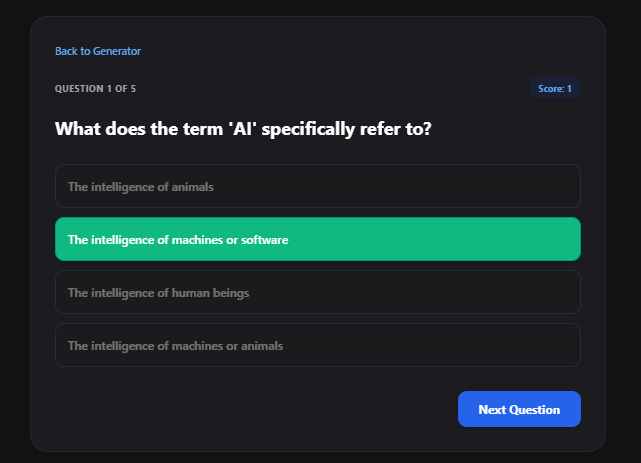

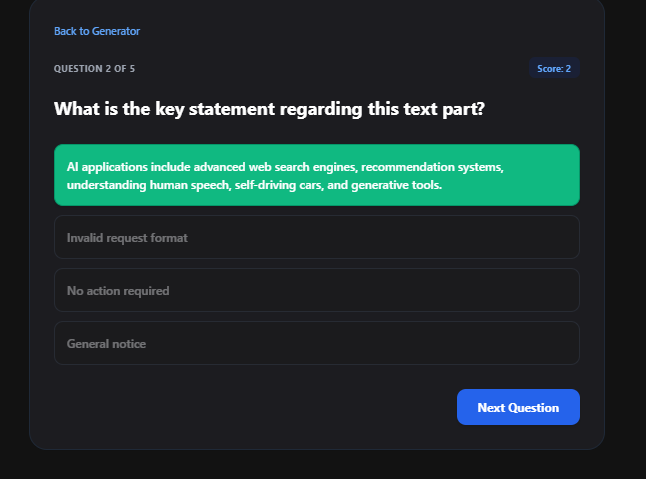

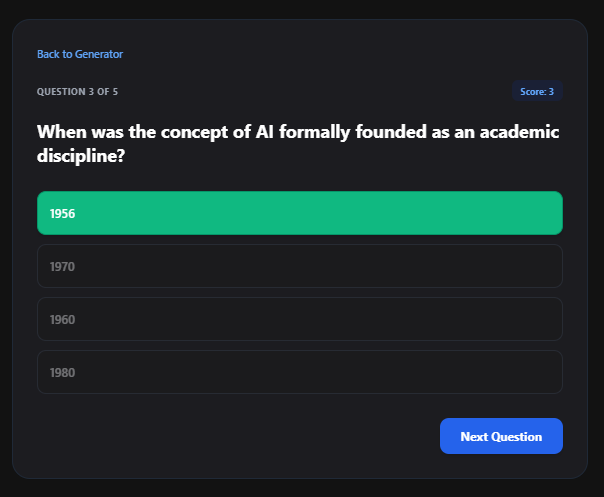

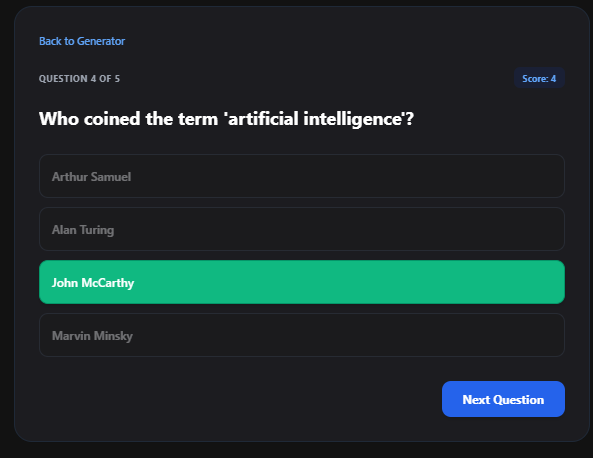

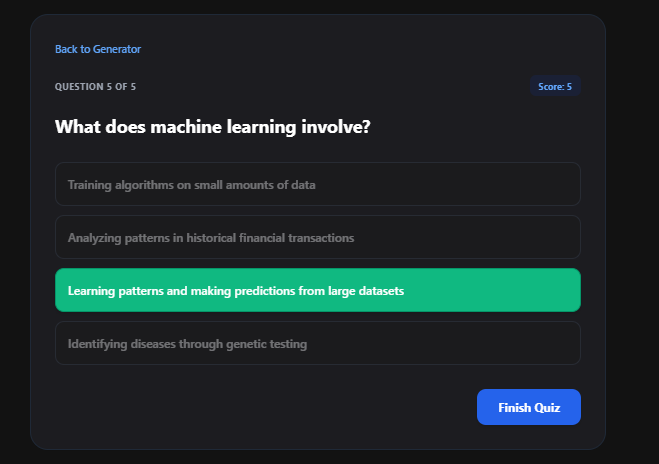

* *Вхідні дані:*

  - *Текст:* AI is the future.
  - *Параметри:* 5 питань, medium складність.
  - *Результат:* Застосунок миттєво заблокував запит і видав повідомлення про помилку "Please enter a longer text for quiz generation.
  - *Аналіз генерацій:* Генерація не відбулася. Вбудований валідатор успішно відпрацював крайовий випадок ще до виклику API, що дозволило уникнути марного навантаження на локальну модель із нерелевантними даними

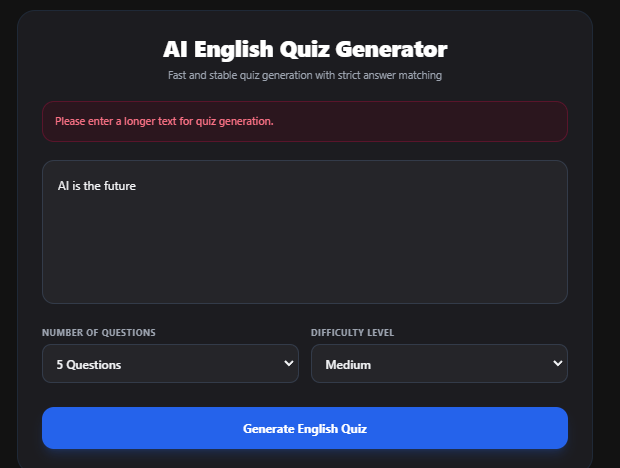

* *Вхідні дані:*

  - *Текст:* Applications and devices equipped with AI can see and identify objects. They can understand and respond to human language. They can learn from new information and experience. They can make detailed recommendations to users and experts. They can act independently, replacing the need for human intelligence or intervention (a classic example being a self-driving car).
  But in 2024, most AI researchers, practitioners and most AI-related headlines are focused on breakthroughs in generative AI (gen AI), a technology that can create original text, images, video and other content. To fully understand generative AI, it’s important to first understand the technologies on which generative AI tools are built: machine learning (ML) and deep learning. Directly underneath AI, we have machine learning, which involves creating models by training an algorithm to make predictions or decisions based on data. It encompasses a broad range of techniques that enable computers to learn from and make inferences based on data without being explicitly programmed for specific tasks.
  There are many types of machine learning techniques or algorithms, including linear regression, logistic regression, decision trees, random forest, support vector machines (SVMs), k-nearest neighbor (KNN), clustering and more. Each of these approaches is suited to different kinds of problems and data.
  But one of the most popular types of machine learning algorithm is called a neural network (or artificial neural network). Neural networks are modeled after the human brain's structure and function. A neural network consists of interconnected layers of nodes (analogous to neurons) that work together to process and analyze complex data. Neural networks are well suited to tasks that involve identifying complex patterns and relationships in large amounts of data.
  The simplest form of machine learning is called supervised learning, which involves the use of labeled data sets to train algorithms to classify data or predict outcomes accurately. In supervised learning, humans pair each training example with an output label. The goal is for the model to learn the mapping between inputs and outputs in the training data, so it can predict the labels of new, unseen data.
  Deep learning is a subset of machine learning that uses multilayered neural networks, called deep neural networks, that more closely simulate the complex decision-making power of the human brain.
  Deep neural networks include an input layer, at least three but usually hundreds of hidden layers, and an output layer, unlike neural networks used in classic machine learning models, which usually have only one or two hidden layers.
  These multiple layers enable unsupervised learning: they can automate the extraction of features from large, unlabeled and unstructured data sets, and make their own predictions about what the data represents.
  Because deep learning doesn’t require human intervention, it enables machine learning at a tremendous scale. It is well suited to natural language processing (NLP), computer vision, and other tasks that involve the fast, accurate identification complex patterns and relationships in large amounts of data. Some form of deep learning powers most of the artificial intelligence (AI) applications in our lives today.
  In a deep neural network, multiple layers of nodes can extract meaning and relationships from large volumes of unstructured, unlabeled data. Generative AI, sometimes called "gen AI", refers to deep learning models that can create complex original content such as long-form text, high-quality images, realistic video or audio and more in response to a user’s prompt or request.
  At a high level, generative models encode a simplified representation of their training data, and then draw from that representation to create new work that’s similar, but not identical, to the original data.
  Generative models have been used for years in statistics to analyze numerical data. But over the last decade, they evolved to analyze and generate more complex data types. This evolution coincided with the emergence of three sophisticated deep learning model types:
  •	Variational autoencoders or VAEs, which were introduced in 2013, and enabled models that could generate multiple variations of content in response to a prompt or instruction.
  •	Diffusion models, first seen in 2014, which add "noise" to images until they are unrecognizable, and then remove the noise to generate original images in response to prompts.
  •	Transformers (also called transformer models), which are trained on sequenced data to generate extended sequences of content (such as words in sentences, shapes in an image, frames of a video or commands in software code). Transformers are at the core of most of today’s headline-making generative AI tools, including ChatGPT and GPT-4, Copilot, BERT, Bard and Midjourney.
  •	Generative AI begins with a "foundation model"; a deep learning model that serves as the basis for multiple different types of generative AI applications.
  •	The most common foundation models today are large language models (LLMs), created for text generation applications. But there are also foundation models for image, video, sound or music generation, and multimodal foundation models that support several kinds of content.
  •	To create a foundation model, practitioners train a deep learning algorithm on huge volumes of relevant raw, unstructured, unlabeled data, such as terabytes or petabytes of data text or images or video from the internet. The training yields a neural network of billions of parameters encoded representations of the entities, patterns and relationships in the data that can generate content autonomously in response to prompts. This is the foundation model.
  •	This training process is compute-intensive, time-consuming and expensive. It requires thousands of clustered graphics processing units (GPUs) and weeks of processing, all of which typically costs millions of dollars. Open source foundation model projects, such as Meta's Llama-2, enable gen AI developers to avoid this step and its costs.
  Next, the model must be tuned to a specific content generation task. This can be done in various ways, including:
  •	Fine-tuning, which involves feeding the model application-specific labeled data, questions or prompts the application is likely to receive, and corresponding correct answers in the wanted format.
  •	Reinforcement learning with human feedback (RLHF), in which human users evaluate the accuracy or relevance of model outputs so that the model can improve itself. This can be as simple as having people type or talk back corrections to a chatbot or virtual assistant.
  Generation, evaluation and more tuning
  Developers and users regularly assess the outputs of their generative AI apps, and further tune the model even as often as once a week for greater accuracy or relevance. In contrast, the foundation model itself is updated much less frequently, perhaps every year or 18 months.
  Another option for improving a gen AI app's performance is retrieval augmented generation (RAG), a technique for extending the foundation model to use relevant sources outside of the training data to refine the parameters for greater accuracy or relevance.
  An AI agent is an autonomous AI program, it can perform tasks and accomplish goals on behalf of a user or another system without human intervention, by designing its own workflow and using available tools (other applications or services).
  Agentic AI is a system of multiple AI agents, the efforts of which are coordinated, or orchestrated, to accomplish a more complex task or a greater goal than any single agent in the system could accomplish.
  Unlike chatbots and other AI models which operate within predefined constraints and require human intervention, AI agents and agentic AI exhibit autonomy, goal-driven behavior and adaptability to changing circumstances. The terms “agent” and “agentic” refer to these models’ agency, or their capacity to act independently and purposefully.
  One way to think of agents is as a natural next step after generative AI. Gen AI models focus on creating content based on learned patterns; agents use that content to interact with each other and other tools to make decisions, solve problems and complete tasks. For example, a gen AI app might be able to tell you the best time to climb Mt. Everest given your work schedule, but an agent can tell you this, and then use an online travel service to book you the best flight and reserve a room in the most convenient hotel in Nepal.
  AI can automate routine, repetitive and often tedious tasks including digital tasks such as data collection, entering and preprocessing, and physical tasks such as warehouse stock-picking and manufacturing processes. This automation frees to work on higher value, more creative work. Whether used for decision support or for fully automated decision-making, AI enables faster, more accurate predictions and reliable, data-driven decisions. Combined with automation, AI enables businesses to act on opportunities and respond to crises as they emerge, in real time and without human intervention. AI can reduce human errors in various ways, from guiding people through the proper steps of a process, to flagging potential errors before they occur, and fully automating processes without human intervention. This is especially important in industries such as healthcare where, for example, AI-guided surgical robotics enable consistent precision.
  Machine learning algorithms can continually improve their accuracy and further reduce errors as they're exposed to more data and "learn" from experience. AI is always on, available around the clock, and delivers consistent performance every time. Tools such as AI chatbots or virtual assistants can lighten staffing demands for customer service or support. In other applications such as materials processing or production lines, AI can help maintain consistent work quality and output levels when used to complete repetitive or tedious tasks.
  - *Параметри:* 10 питань, medium складність.
  - *Результат:* Застосунок успішно опрацював великий обсяг тексту, згенерувавши 10 питань без критичних збоїв. Тест успішно пройдено до кінця.
  - *Аналіз генерацій:*
    - Питання 1, Питання 4, Питання 6, Питання 7 та Питання 8 демонструють ідеальну роботу локальної моделі.
    - Питання 2, Питання 3, Питання 5, Питання 9 та Питання 10 демонструють обмеження моделі, у 2-му, 3-му та 5-му спрацював резервний захист через нездатність моделі видати валідний JSON, а в 9-му та 10-му вона припустилася логічної помилки, згенерувавши як хибні варіанти відповідей ті факти, що насправді є правильними згідно з текстом.

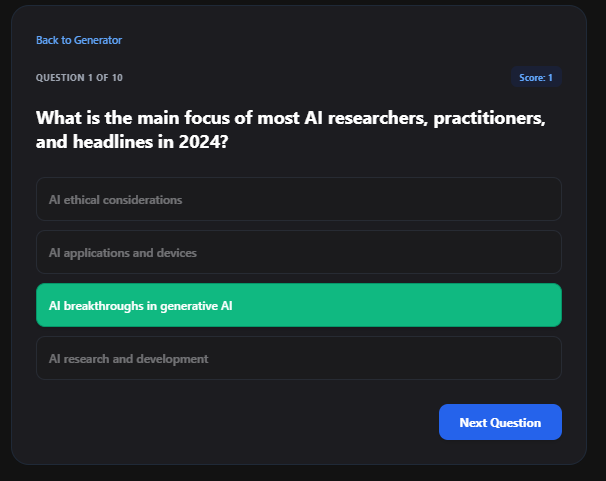

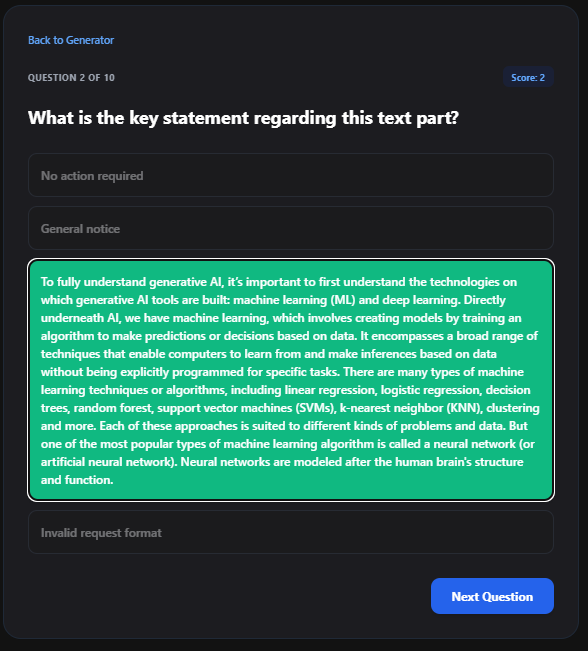

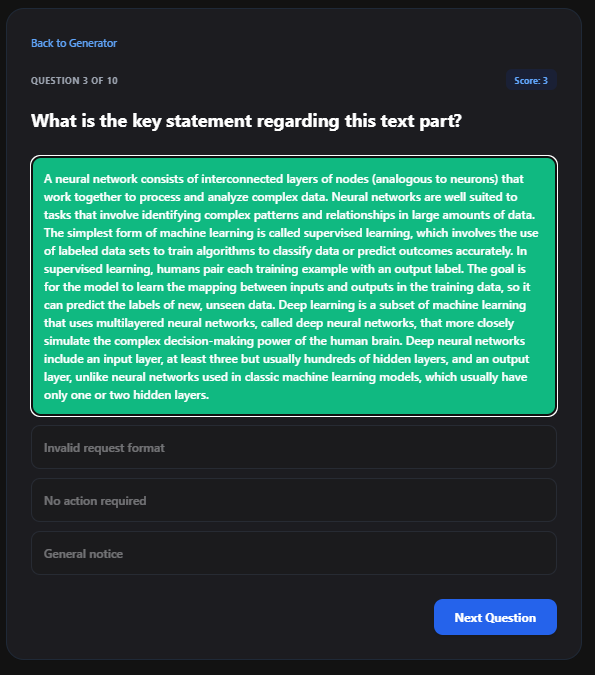

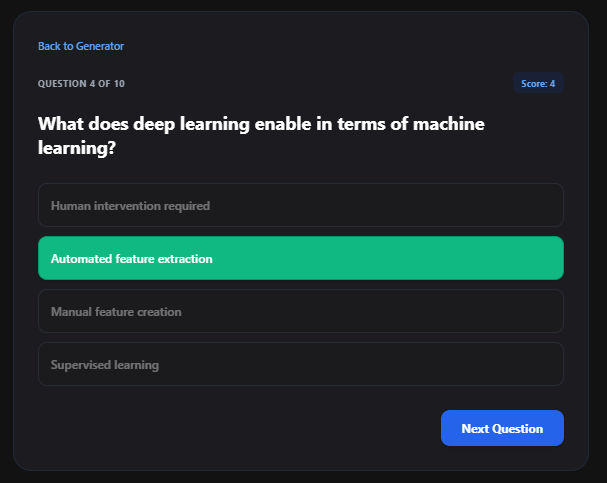

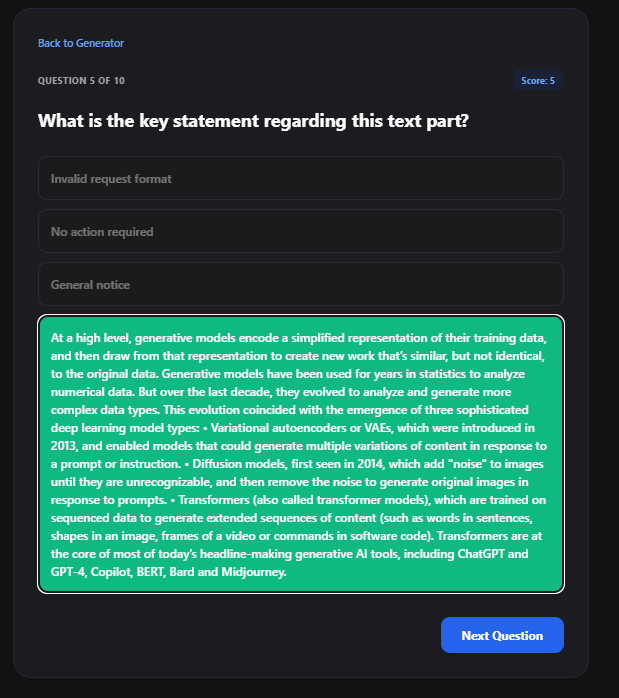

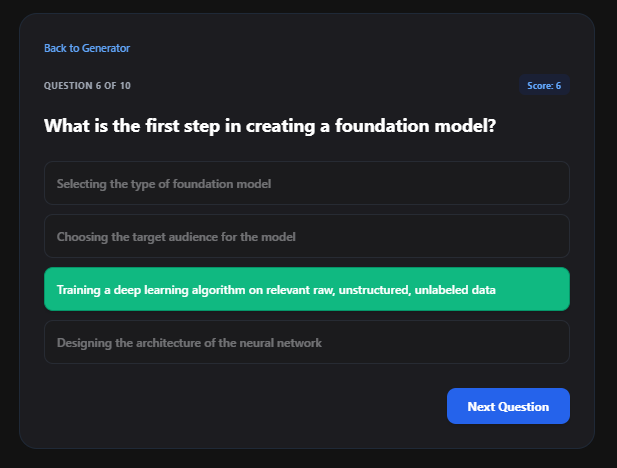

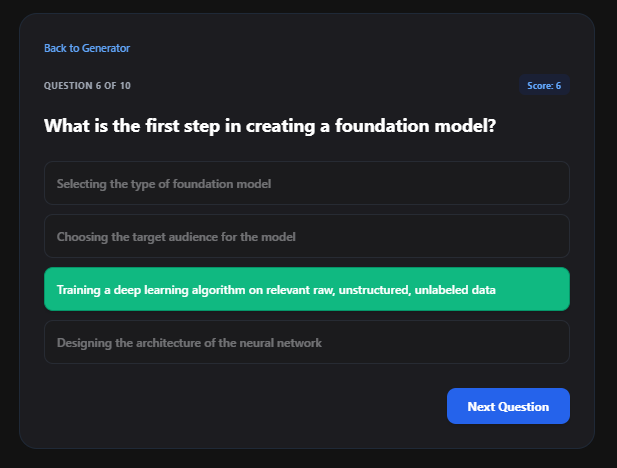

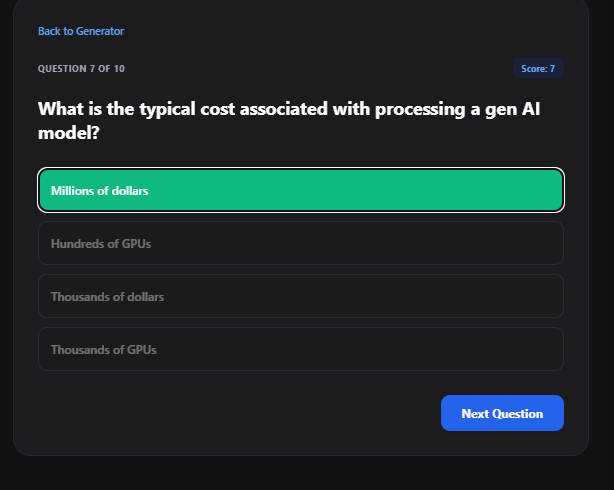

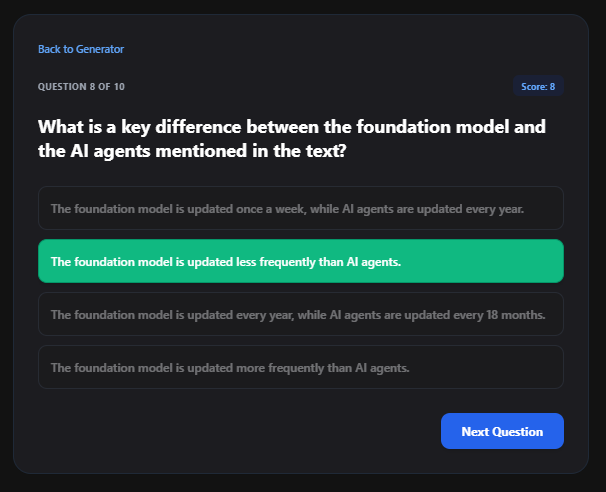

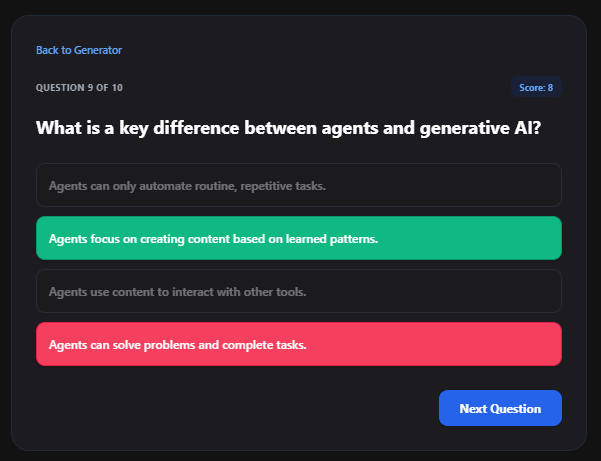

* *Вхідні дані:*

  - *Текст:* Відновлювана енергетика — це галузь енергетики, що спеціалізується на використанні невичерпних джерел енергії, таких як сонячне випромінювання, вітер, рух води та геотермальне тепло. На відміну від викопного палива (вугілля, нафти, газу), використання відновлюваних джерел завдає значно меншої шкоди навколишньому середовищу та допомагає боротися зі зміною клімату. Сьогодні багато країн світу активно інвестують у будівництво сонячних та вітрових електростанцій, прагнучи досягти вуглецевої нейтральності до 2050 року.
  - *Параметри:* 5 питань, medium складність.
  - *Результат:* Застосунок не впав із критичною помилкою, однак частково згенерував англомовні питання-заглушки замість повноцінного україномовного квізу.
  - *Аналіз генерацій:*
    - Питання 2 та Питання 3 демонструють здатність локальної моделі генерувати коректні англомовні запитання на основі україномовного тексту.
    - Питання 1, Питання 4 та Питання 5 демонструють обмеження моделі при обробці нецільової мови. У 4-му та 5-му питаннях спрацював резервний захист через нездатність моделі видати валідний JSON. У 1-му питанні модель припустилася логічної помилки, згенерувавши як хибний варіант відповіді той факт, що насправді є правильним згідно з текстом, водночас сформулювавши хибні варіанти неіснуючими словами.

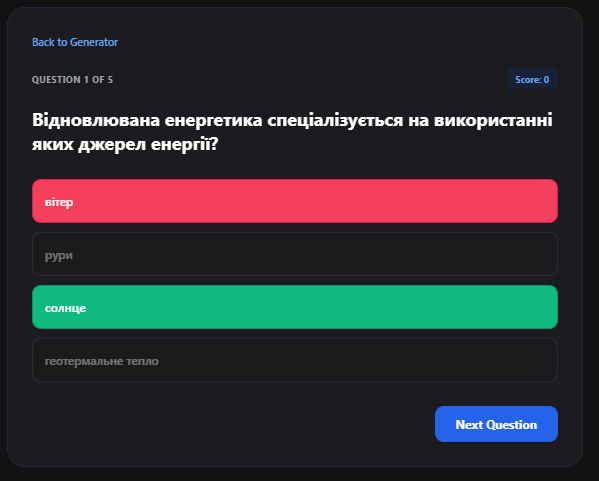

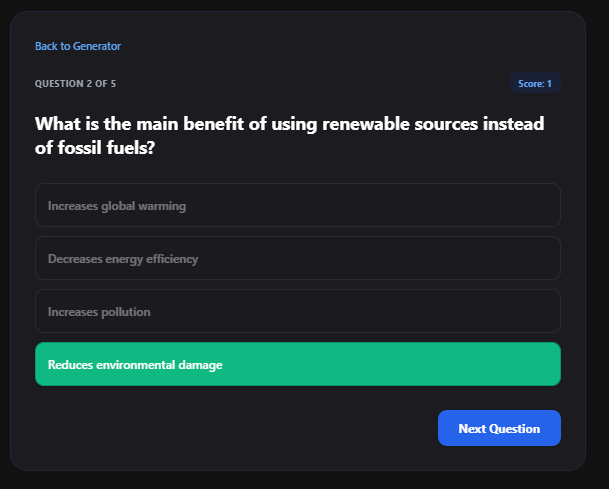

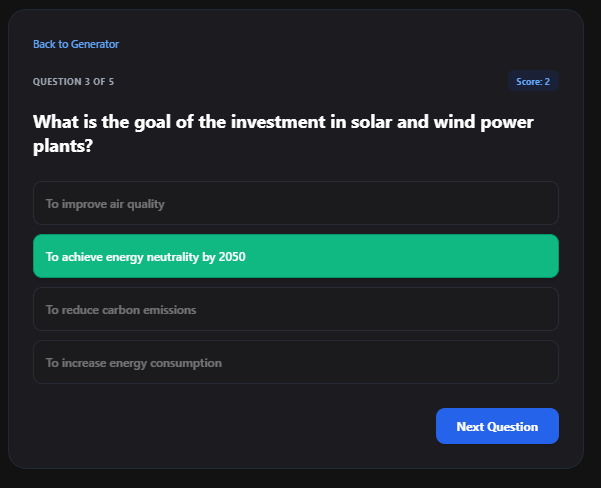

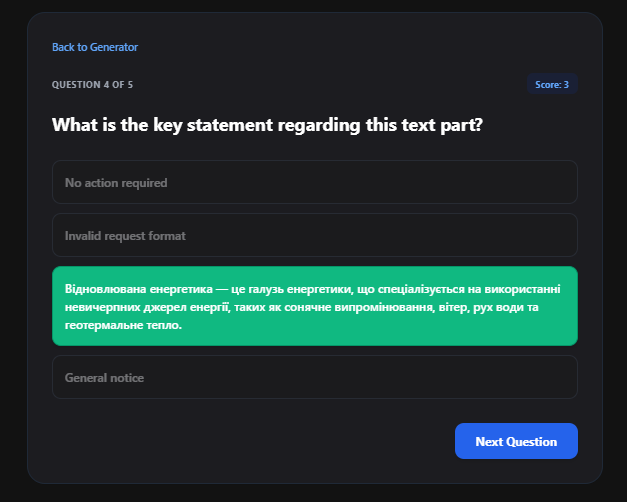

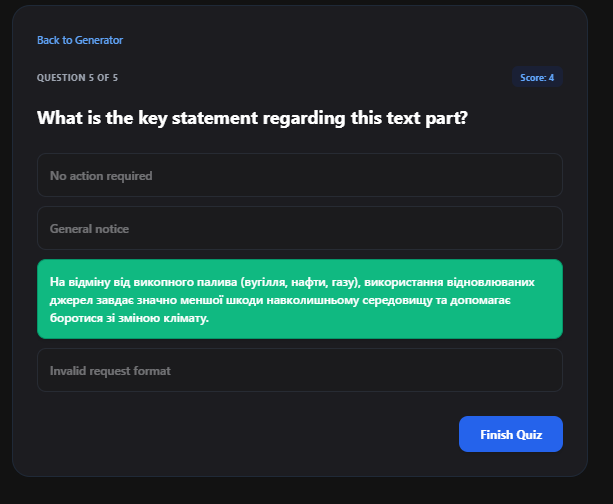

* *Вхідні дані:*

  - *Текст:* The sun is a star at the center of the Solar System. It is a nearly perfect sphere of hot plasma. The Earth orbits the sun.
  - *Параметри:* 5 питань, medium складність.
  - *Результат:* Застосунок успішно обробив запит без критичних збоїв, проте через екстремально малий обсяг вхідного тексту зміг згенерувати лише два повноцінних запитання, автоматично застосувавши резервний механізм (Fallback) для інших трьох.
  - *Аналіз генерацій:*
    - Питання 1 та Питання 5 демонструють ідеальну роботу локальної моделі з наявним фактажем. Вона успішно сформулювала запитання про центр Сонячної системи та геометричну форму плазми, якісно підібравши логічні помилкові варіанти з відповідних категорій, назви інших планет та інші геометричні фігури.
    - Питання 2, Питання 3 та Питання 4 демонструють обмеження при роботі з дуже короткими текстами. Оскільки вхідний текст складався лише з трьох коротких речень, моделі забракло контексту для створення п'яти унікальних запитань. Це призвело до порушення формату JSON, через що спрацював резервний захист, який просто підставив речення з тексту як правильні варіанти відповідей до шаблонного питання-заглушки.

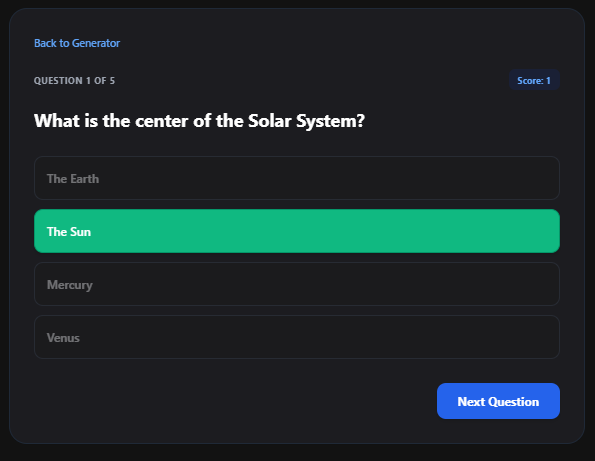

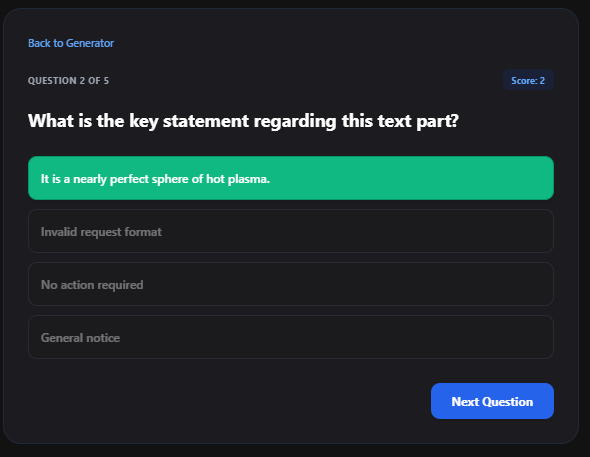

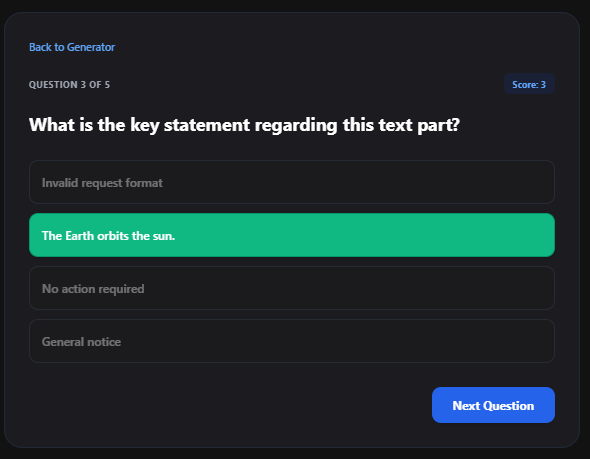

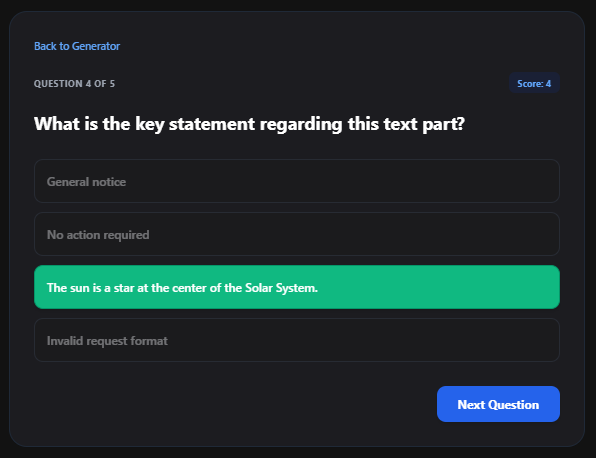

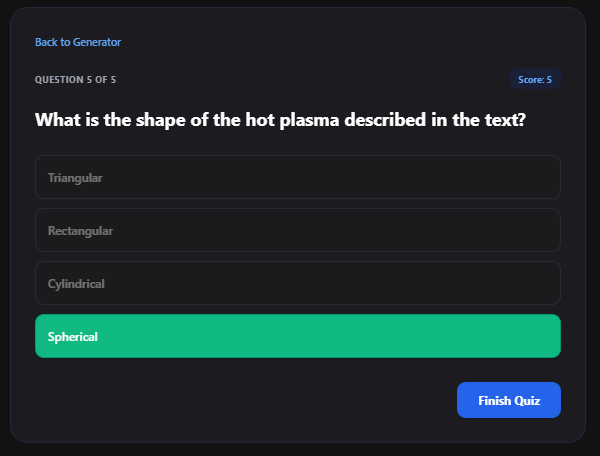

**Аналіз помилок та спроби їх виправлення:**

Найбільшим обмеженням обраної моделі стала її нездатність коректно працювати з україномовним текстом, що було очікуваним з огляду на жорсткі ліміти відеопам'яті та малу кількість параметрів обраної моделі. Під час тестування українською мовою модель грубо порушувала граматику, вигадувала неіснуючі слова та використовувала технічні заглушки, оскільки не могла самостійно сформулювати логічні хибні чи правильні варіанти відповідей.

Для вирішення цієї проблеми було здійснено низку кроків: застосування few-shot промптингу з додаванням прикладів очікуваного результату, додаткове розбиття тексту на ще дрібніші запити, а також тонке налаштування температури генерації та ліміту токенів. Проте всі ці заходи виявилися безрезультатними, через малий обсяг параметрів нейромережа занадто швидко втрачала контекст і починала генерувати незв'язну інформацію.

За підсумками цих спроб було зроблено висновок, що проблема полягає у слабкості самої моделі. Єдиним доцільним рішенням у поточних апаратних умовах стало залишити застосунок виключно англомовним, оскільки з англійською мовою модель демонструє хоч і не ідеальний, але цілком прийнятний та адекватний результат.

#### 4.8. Висновок:

Дослідження підтвердило можливість ефективного використання локальних мовних моделей на обмеженому апаратному забезпеченні. Розрахунки та подальше бенчмаркування довели, що вибір оптимальної квантизації дозволяє повністю розмістити модель у відеопам'яті та забезпечити стабільну швидкість генерації токенів. Спроби екстремальної оптимізації за рахунок зменшення кількості параметрів призводять до критичної деградації логіки та появи галюцинацій, тому використання базової стабільної моделі виявилося єдиним доцільним рішенням.

Розроблений застосунок успішно інтегрує локальну нейромережу через OpenAI-сумісний API для безперебійного виконання цільової задачі. Застосування суворих параметрів генерації, структурного промптингу та вбудованих механізмів валідації забезпечило відмовостійкість системи навіть при некоректних відповідях. Тестування показало, що архітектура надійно справляється з прямолінійним вилученням фактів, однак виявляє когнітивні межі малої моделі при спробах опрацювати складні логічні інструкції чи тексти нецільовою мовою.